Dataset: Diabetes Readmission Dataset

https://www.kaggle.com/datasets/hotsonhonet/diabetes-readmission-dataset?resource=download

In [ ]:
#Data
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("diabetic_data.csv")

# Basic inspection
print("Shape:", df.shape)
df.head()

Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

In [ ]:
#Intelligence
df['readmitted'].value_counts()

,count
readmitted,
NO,54864
>30,35545
<30,11357


In [ ]:
df['readmit_30'] = df['readmitted'].apply(lambda x: 1 if x == '<30' else 0)
df['readmit_30'].value_counts()

,count
readmit_30,
0,90409
1,11357


In [ ]:
risk_df = df[[
    'time_in_hospital',
    'number_inpatient',
    'number_emergency',
    'number_outpatient',
    'num_medications',
    'num_lab_procedures',
    'readmit_30'
]].copy()

In [ ]:
risk_df.isnull().sum()
risk_df.fillna(0, inplace=True)

In [ ]:
risk_df.fillna(0, inplace=True)

In [ ]:
risk_df['long_stay'] = (risk_df['time_in_hospital'] >= 7).astype(int)
risk_df['frequent_inpatient'] = (risk_df['number_inpatient'] >= 2).astype(int)
risk_df['emergency_visits'] = (risk_df['number_emergency'] >= 1).astype(int)
risk_df['many_meds'] = (risk_df['num_medications'] >= 10).astype(int)

In [ ]:
risk_df['risk_score'] = (
    risk_df['long_stay'] +
    risk_df['frequent_inpatient'] +
    risk_df['emergency_visits'] +
    risk_df['many_meds']
)

risk_df[['risk_score']].describe()

,risk_score
count,101766.000000
mean,1.261698
std,0.835914
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [ ]:
# Average readmission rate by risk score
risk_df.groupby('risk_score')['readmit_30'].mean()

,readmit_30
risk_score,
0,0.070183
1,0.095418
2,0.139458
3,0.208570
4,0.225951


In [ ]:
risk_df['risk_score'].value_counts().sort_index()

,count
risk_score,
0,16343
1,50934
2,26897
3,6698
4,894


In [ ]:
#User Experience (UX)
# Auto-generate risk level from risk score
def assign_risk_level(score):
    if score <= 1:
        return "Low"
    elif score <= 3:
        return "Medium"
    else:
        return "High"

risk_df['risk_level'] = risk_df['risk_score'].apply(assign_risk_level)

# Check distribution
risk_df['risk_level'].value_counts()

,count
risk_level,
Low,67277
Medium,33595
High,894


In [ ]:
ux_summary = (
    risk_df
    .groupby('risk_level')['readmit_30']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'readmission_rate'})
)

ux_summary

,count,readmission_rate
risk_level,,
High,894,0.225951
Low,67277,0.089288
Medium,33595,0.153237


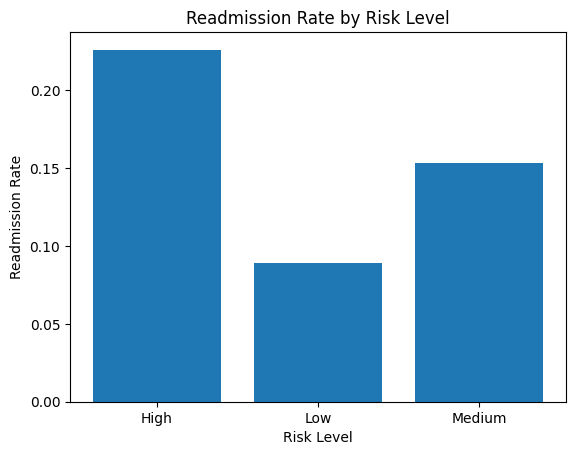

In [ ]:
import matplotlib.pyplot as plt

# Create bar chart
plt.figure()
plt.bar(ux_summary.index, ux_summary['readmission_rate'])
plt.xlabel("Risk Level")
plt.ylabel("Readmission Rate")
plt.title("Readmission Rate by Risk Level")

plt.show()

In [ ]:
#Value
# Identify high-risk patients for focused discharge review
high_risk_patients = risk_df[risk_df['risk_level'] == 'High']

high_risk_patients.shape

(894, 14)

In [ ]:
# Assign follow-up actions based on risk level
def followup_plan(risk_level):
    if risk_level == 'High':
        return 'Immediate discharge review + follow-up within 48 hours'
    elif risk_level == 'Medium':
        return 'Standard discharge review + follow-up within 7 days'
    else:
        return 'Routine discharge process'

risk_df['followup_plan'] = risk_df['risk_level'].apply(followup_plan)

risk_df['followup_plan'].value_counts()

,count
followup_plan,
Routine discharge process,67277
Standard discharge review + follow-up within 7 days,33595
Immediate discharge review + follow-up within 48 hours,894


In [ ]:
# Monitor readmission rates by risk level
value_monitoring = (
    risk_df
    .groupby('risk_level')['readmit_30']
    .mean()
    .reset_index(name='readmission_rate')
)

value_monitoring

,risk_level,readmission_rate
0,High,0.225951
1,Low,0.089288
2,Medium,0.153237


In [ ]:
#Opportunity (Machine Learning)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.model_selection import train_test_split

In [ ]:
# Features
X = risk_df[[
    'time_in_hospital',
    'number_inpatient',
    'number_emergency',
    'number_outpatient',
    'num_medications',
    'num_lab_procedures'
]]

# Target
y = risk_df['readmit_30']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

In [ ]:
# Predict probabilities
risk_df['rf_readmission_probability'] = rf_model.predict_proba(X)[:, 1]

risk_df[['risk_level', 'rf_readmission_probability']].head()

,risk_level,rf_readmission_probability
0,Low,0.208907
1,Low,0.421359
2,Low,0.498656
3,Low,0.419694
4,Low,0.300079


In [ ]:
y_test_prob = rf_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_test_prob)
roc_auc

np.float64(0.6255874473981226)

In [ ]:
# Top 10 highest-risk patients (ML-based)
top_rf_risk = risk_df.sort_values(
    by='rf_readmission_probability', ascending=False
).head(10)

top_rf_risk[['risk_level', 'rf_readmission_probability']]

,risk_level,rf_readmission_probability
88075,Medium,0.909872
26042,Medium,0.898625
25881,Medium,0.896184
101579,Medium,0.891713
94882,Medium,0.891010
46914,Medium,0.890723
88055,Medium,0.884646
38644,Medium,0.881256
100386,Medium,0.879283
73751,Medium,0.878540
